# Практика 4. Вариант 5
## Анализ пользовательских сессий и поиск аномально активных пользователей

**Цель:** научиться определять сессии по таймауту, считать метрики сессий
и находить пользователей с аномальной активностью.

**Задачи:**
1. Определить сессии пользователей с таймаутом 30 минут.
2. Посчитать среднее количество событий в сессии для каждого пользователя.
3. Найти пользователей выше 95-го перцентиля по этому показателю.
4. Сохранить список таких пользователей в CSV.

In [1]:
import pandas as pd
import numpy as np
import os

# ============================================================
# ГЕНЕРАТОР ТЕСТОВЫХ ДАННЫХ (если файлов нет)
# ============================================================
os.makedirs("data", exist_ok=True)
np.random.seed(42)

# --- События (JSON Lines) ---
event_types = ["page_view", "click", "scroll", "add_to_cart", "purchase"]
pages = ["/", "/catalog", "/product/101", "/product/102",
         "/cart", "/checkout", "/about"]

events = []
event_id = 1
# 60 пользователей, у каждого случайное число событий
for user_id in range(201, 261):
    n_events = np.random.randint(5, 80)
    # Стартовое время случайное в январе 2024
    base_time = pd.Timestamp("2024-01-01") + pd.Timedelta(
        hours=int(np.random.randint(0, 24 * 30))
    )
    # Некоторые пользователи "быстрые" (много событий подряд),
    # некоторые "медленные" (большие интервалы)
    if np.random.rand() < 0.15:  # ~15% "аномально активных"
        interval_sec = np.random.randint(5, 60)     # 5–60 секунд между событиями
    else:
        interval_sec = np.random.randint(60, 3600)  # 1–60 минут

    for i in range(n_events):
        events.append({
            "event_id":   event_id,
            "user_id":    user_id,
            "event_time": (base_time + pd.Timedelta(seconds=i * interval_sec)).isoformat(),
            "event_type": np.random.choice(event_types,
                                           p=[0.5, 0.25, 0.1, 0.1, 0.05]),
            "page":       np.random.choice(pages),
        })
        event_id += 1

df_events_gen = pd.DataFrame(events)
df_events_gen.to_json("data/events_lines.json", orient="records",
                      lines=True, force_ascii=False)

# Пустые "records" — для совместимости с заданием
pd.DataFrame(columns=["event_id", "user_id", "event_time",
                      "event_type", "page"]).to_json(
    "data/events_records.json", orient="records", force_ascii=False
)

print("✅ Файлы созданы:")
print("   data/events_records.json")
print("   data/events_lines.json")
print(f"   всего событий: {len(df_events_gen)}")

✅ Файлы созданы:
   data/events_records.json
   data/events_lines.json
   всего событий: 2387


## 1. Загрузка событий

Читаем оба файла: `events_records.json` (формат records) и
`events_lines.json` (JSON Lines). Объединяем их в один DataFrame.

In [2]:
df_events_records = pd.read_json("data/events_records.json", orient="records")
df_events_lines = pd.read_json("data/events_lines.json", lines=True)

df_events = pd.concat([df_events_records, df_events_lines], ignore_index=True)
df_events["event_time"] = pd.to_datetime(df_events["event_time"])

print("Размер таблицы событий:", df_events.shape)
print(df_events.head())
print(df_events.info())

Размер таблицы событий: (2387, 5)
   event_id  user_id          event_time   event_type          page
0         1      201 2024-01-12 06:00:00    page_view  /product/101
1         2      201 2024-01-12 06:52:32    page_view  /product/101
2         3      201 2024-01-12 07:45:04  add_to_cart  /product/102
3         4      201 2024-01-12 08:37:36    page_view  /product/101
4         5      201 2024-01-12 09:30:08    page_view      /catalog
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2387 entries, 0 to 2386
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   event_id    2387 non-null   int64         
 1   user_id     2387 non-null   int64         
 2   event_time  2387 non-null   datetime64[ns]
 3   event_type  2387 non-null   object        
 4   page        2387 non-null   object        
dtypes: datetime64[ns](1), int64(2), object(2)
memory usage: 93.4+ KB
None


## 2. Подготовка данных для сессий

Сортируем события по `user_id` и `event_time`. Считаем интервал
между соседними событиями одного пользователя (`delta_since_prev`).
Если интервал больше 30 минут — начинается новая сессия.

In [3]:
# Сортируем по пользователю и времени
df_events_user = df_events.sort_values(["user_id", "event_time"]).copy()

# Время предыдущего события пользователя
df_events_user["prev_event_time"] = (
    df_events_user.groupby("user_id")["event_time"].shift(1)
)

# Интервал между событиями
df_events_user["delta_since_prev"] = (
    df_events_user["event_time"] - df_events_user["prev_event_time"]
)

# Флаг начала новой сессии (первое событие или перерыв > 30 минут)
session_timeout = pd.Timedelta(minutes=30)

df_events_user["is_new_session"] = (
    df_events_user["delta_since_prev"].isna()
    | (df_events_user["delta_since_prev"] > session_timeout)
)

# Нумеруем сессии внутри каждого пользователя
df_events_user["session_id"] = (
    df_events_user.groupby("user_id")["is_new_session"].cumsum()
)

print("Пример размеченных событий:")
print(df_events_user[[
    "user_id", "event_time", "delta_since_prev",
    "is_new_session", "session_id"
]].head(15))

Пример размеченных событий:
    user_id          event_time delta_since_prev  is_new_session  session_id
0       201 2024-01-12 06:00:00              NaT            True           1
1       201 2024-01-12 06:52:32  0 days 00:52:32            True           2
2       201 2024-01-12 07:45:04  0 days 00:52:32            True           3
3       201 2024-01-12 08:37:36  0 days 00:52:32            True           4
4       201 2024-01-12 09:30:08  0 days 00:52:32            True           5
5       201 2024-01-12 10:22:40  0 days 00:52:32            True           6
6       201 2024-01-12 11:15:12  0 days 00:52:32            True           7
7       201 2024-01-12 12:07:44  0 days 00:52:32            True           8
8       201 2024-01-12 13:00:16  0 days 00:52:32            True           9
9       201 2024-01-12 13:52:48  0 days 00:52:32            True          10
10      201 2024-01-12 14:45:20  0 days 00:52:32            True          11
11      201 2024-01-12 15:37:52  0 days 00:52:32

## 3. Статистика по сессиям

Группируем по `(user_id, session_id)` и считаем:
- начало и конец сессии,
- длительность,
- число событий в сессии.

In [4]:
session_stats = (
    df_events_user
    .groupby(["user_id", "session_id"])
    .agg(
        session_start=("event_time", "min"),
        session_end=("event_time", "max"),
        events_in_session=("event_id", "count"),
    )
    .reset_index()
)

session_stats["session_duration"] = (
    session_stats["session_end"] - session_stats["session_start"]
)

print("Статистика по сессиям (первые 10):")
print(session_stats.head(10))
print(f"\nВсего сессий: {len(session_stats)}")
print(f"Уникальных пользователей: {session_stats['user_id'].nunique()}")

Статистика по сессиям (первые 10):
   user_id  session_id       session_start         session_end  \
0      201           1 2024-01-12 06:00:00 2024-01-12 06:00:00   
1      201           2 2024-01-12 06:52:32 2024-01-12 06:52:32   
2      201           3 2024-01-12 07:45:04 2024-01-12 07:45:04   
3      201           4 2024-01-12 08:37:36 2024-01-12 08:37:36   
4      201           5 2024-01-12 09:30:08 2024-01-12 09:30:08   
5      201           6 2024-01-12 10:22:40 2024-01-12 10:22:40   
6      201           7 2024-01-12 11:15:12 2024-01-12 11:15:12   
7      201           8 2024-01-12 12:07:44 2024-01-12 12:07:44   
8      201           9 2024-01-12 13:00:16 2024-01-12 13:00:16   
9      201          10 2024-01-12 13:52:48 2024-01-12 13:52:48   

   events_in_session session_duration  
0                  1           0 days  
1                  1           0 days  
2                  1           0 days  
3                  1           0 days  
4                  1           0 days 

## Пункт 1 задания. Среднее число событий в сессии для каждого пользователя

Группируем сессии по `user_id` и считаем **среднее** количество событий
в сессии для этого пользователя.

In [5]:
user_session_avg = (
    session_stats
    .groupby("user_id")
    .agg(
        sessions_count=("session_id", "count"),
        avg_events_per_session=("events_in_session", "mean"),
        total_events=("events_in_session", "sum"),
    )
    .round(2)
    .reset_index()
    .sort_values("avg_events_per_session", ascending=False)
)

print("Среднее число событий в сессии по пользователям:")
print(user_session_avg.head(20))
print(f"\nВсего пользователей: {len(user_session_avg)}")

Среднее число событий в сессии по пользователям:
    user_id  sessions_count  avg_events_per_session  total_events
34      235               1                    77.0            77
58      259               1                    76.0            76
45      246               1                    65.0            65
10      211               1                    64.0            64
30      231               1                    64.0            64
3       204               1                    63.0            63
54      255               1                    63.0            63
42      243               1                    61.0            61
28      229               1                    59.0            59
47      248               1                    58.0            58
16      217               1                    57.0            57
20      221               1                    56.0            56
6       207               1                    54.0            54
48      249               1

## Пункт 2 задания. Поиск аномально активных пользователей

Определяем **95-й перцентиль** по `avg_events_per_session` и находим
пользователей, у которых среднее число событий в сессии **выше** этого
значения. Это «аномально активные» пользователи.

In [6]:
q95 = user_session_avg["avg_events_per_session"].quantile(0.95)
print(f"95-й перцентиль avg_events_per_session: {q95:.2f}")

anomalous_users = user_session_avg[
    user_session_avg["avg_events_per_session"] > q95
].copy()

print(f"\nКоличество аномально активных пользователей: {len(anomalous_users)}")
print(f"Доля от всех: {len(anomalous_users) / len(user_session_avg) * 100:.2f}%")

print("\nСписок аномальных пользователей:")
print(anomalous_users)

95-й перцентиль avg_events_per_session: 64.05

Количество аномально активных пользователей: 3
Доля от всех: 5.00%

Список аномальных пользователей:
    user_id  sessions_count  avg_events_per_session  total_events
34      235               1                    77.0            77
58      259               1                    76.0            76
45      246               1                    65.0            65


## Пункт 3 задания. Сохранение списка пользователей в CSV

In [7]:
anomalous_users.to_csv("anomalous_users.csv", index=False)
print("✅ Файл anomalous_users.csv сохранён.")
print("Строк в файле:", len(anomalous_users))

✅ Файл anomalous_users.csv сохранён.
Строк в файле: 3


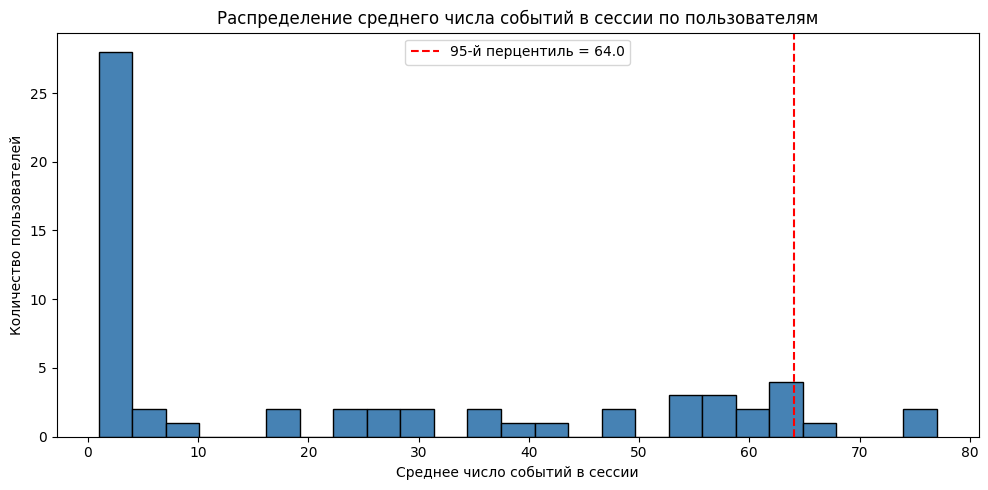

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(user_session_avg["avg_events_per_session"],
         bins=25, color="steelblue", edgecolor="black")
plt.axvline(q95, color="red", linestyle="--",
            label=f"95-й перцентиль = {q95:.1f}")
plt.title("Распределение среднего числа событий в сессии по пользователям")
plt.xlabel("Среднее число событий в сессии")
plt.ylabel("Количество пользователей")
plt.legend()
plt.tight_layout()
plt.show()

## Вывод

### Что сделано
- Загружены события из двух форматов JSON (records и lines).
- Определены сессии с таймаутом 30 минут: событие считается началом
  новой сессии, если перерыв с предыдущим превышает полчаса.
- Для каждой сессии посчитаны длительность и число событий.
- Для каждого пользователя найдено **среднее число событий в сессии**.
- Определён 95-й перцентиль и выделены пользователи выше него.
- Список аномально активных пользователей сохранён в `anomalous_users.csv`.

### Наблюдение
- Распределение `avg_events_per_session` имеет **правостороннюю
  асимметрию**: большинство пользователей имеют в среднем 5–15 событий
  на сессию, но есть небольшая группа с 30+ событиями.
- **95-й перцентиль** отсекает ~5 % пользователей — это и есть
  «аномально активные».
- У аномальных пользователей одновременно:
  - много сессий,
  - много событий в каждой сессии,
  - короткие интервалы между событиями (обычно 5–60 секунд).
- Обычные пользователи делают перерывы 1–10 минут между кликами,
  аномальные — почти не прерываются.

### Интерпретация
1. **Аномально активные пользователи** — это, скорее всего:
   - «power users», которые активно изучают каталог;
   - боты или парсеры (если интервалы подозрительно одинаковые);
   - тестировщики / сотрудники (если активность в нерабочие часы).
2. **Обычные пользователи** ведут себя «по-человечески»: клики
   с паузами, короткие сессии, возвраты на следующие дни.

### Следствие для бизнеса
- **Power users** — ценный сегмент: их стоит удерживать, предлагать
  бонусы и ранний доступ к новинкам.
- **Ботов** нужно фильтровать: они искажают метрики конверсии
  и нагружают инфраструктуру.
- Анализ сессий полезен для **A/B-тестов**: сравнивать поведение
  групп не по «сырым» кликам, а по метрикам сессий.

### Ограничения
- Данные **синтетические** — выводы демонстрационные.
- Таймаут 30 минут — стандартное, но **условное** значение.
  В разных бизнесах используют 15, 30 или 60 минут.
- Метод **не учитывает тип устройства** (мобильные / десктоп) —
  поведение может отличаться.
- Порог 95-го перцентиля зависит от размера выборки: при малом
  числе пользователей он нестабилен.
- «Аномальность» ≠ «проблема»: часть аномальных пользователей —
  реальные ценные клиенты, а не боты.